# Этап 3. Линейная модель (П2–П5)

Базовая модель П1 лежит в `src/train.py`. Здесь исследование для П2–П5.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, validation_curve
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, KBinsDiscretizer
from sklearn.linear_model import LinearRegression, Ridge, LassoCV

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/clean.csv")
num_cols = ["temp", "humidity", "wind", "visibility", "dew_point", "solar", "rainfall", "snowfall"]
cat_cols = ["season", "holiday", "weekend"]
train, test = train_test_split(df, test_size=0.25, random_state=42)
X_train, y_train = train[["hour"] + num_cols + cat_cols], train["count"]

def make_prep(hour_bins=0, strategy="uniform", num=num_cols, cat=cat_cols, drop=None):
    numpipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    catpipe = make_pipeline(SimpleImputer(strategy="most_frequent"),
                            OneHotEncoder(handle_unknown="ignore", drop=drop))
    if hour_bins:
        return make_column_transformer(
            (numpipe, num),
            (KBinsDiscretizer(n_bins=hour_bins, encode="onehot", strategy=strategy), ["hour"]),
            (catpipe, cat))
    return make_column_transformer((numpipe, ["hour"] + num), (catpipe, cat))

def cv_r2(model):
    return cross_val_score(model, X_train, y_train, cv=5, scoring="r2").mean()

print(df.shape, train.shape, test.shape)

(8465, 13) (6348, 13) (2117, 13)


## П2. Формула МНК тремя способами

In [2]:
print(train[["hour"] + num_cols].corrwith(train["count"]).round(2).sort_values())

humidity     -0.21
snowfall     -0.15
rainfall     -0.13
wind          0.13
visibility    0.21
solar         0.27
dew_point     0.40
hour          0.42
temp          0.56
dtype: float64


Сильнее всего с числом аренд связана температура `temp`. Строим парную регрессию `count ~ temp`.

In [3]:
x = train["temp"].to_numpy()
y = train["count"].to_numpy()
X = np.column_stack([np.ones(len(x)), x])

w_inv   = np.linalg.inv(X.T @ X) @ X.T @ y
w_solve = np.linalg.solve(X.T @ X, X.T @ y)
w_lstsq = np.linalg.lstsq(X, y, rcond=None)[0]
lr = LinearRegression().fit(x.reshape(-1, 1), y)
print("inv    ", w_inv.round(2))
print("solve  ", w_solve.round(2))
print("lstsq  ", w_lstsq.round(2))
print("sklearn", np.r_[lr.intercept_, lr.coef_].round(2))

inv     [346.01  30.23]
solve   [346.01  30.23]
lstsq   [346.01  30.23]
sklearn [346.01  30.23]


In [4]:
X2 = np.column_stack([X, x])  # копия столбца temp
print("rank X2 =", np.linalg.matrix_rank(X2), "из", X2.shape[1], "столбцов;  det(XᵀX) =", np.linalg.det(X2.T @ X2))
for name, f in [("inv",   lambda: np.linalg.inv(X2.T @ X2) @ X2.T @ y),
                ("solve", lambda: np.linalg.solve(X2.T @ X2, X2.T @ y)),
                ("lstsq", lambda: np.linalg.lstsq(X2, y, rcond=None)[0]),
                ("sklearn", lambda: (lambda m: np.r_[m.intercept_, m.coef_])(
                     LinearRegression().fit(np.column_stack([x, x]), y)))]:
    try:
        w = f()
        print(f"{name:8}", w.round(2), " прогноз совпадает:", np.allclose(X2 @ w, X @ w_solve))
    except np.linalg.LinAlgError as e:
        print(f"{name:8} ошибка: {e}")

rank X2 = 2 из 3 столбцов;  det(XᵀX) = 0.0
inv      ошибка: Singular matrix
solve    ошибка: Singular matrix
lstsq    [346.01  15.11  15.11]  прогноз совпадает: True
sklearn  [346.01  15.11  15.11]  прогноз совпадает: True


**Вывод П2.**
- Все три способа и `LinearRegression` дают один ответ, count ≈ 346 + 30,2 · temp. Каждый градус добавляет примерно 30 аренд в час.
- С копией столбца у X три столбца, но ранг 2, и det(XᵀX) = 0. У такой матрицы нет обратной, поэтому `inv` и `solve` падают с ошибкой `Singular matrix`.
- `lstsq` и `LinearRegression` работают. Подходящих решений бесконечно много, и они берут то, где веса самые маленькие. Вес делится поровну, 15,11 + 15,11 = 30,22. Прогноз не меняется.

## П3. Час суток как нелинейный признак

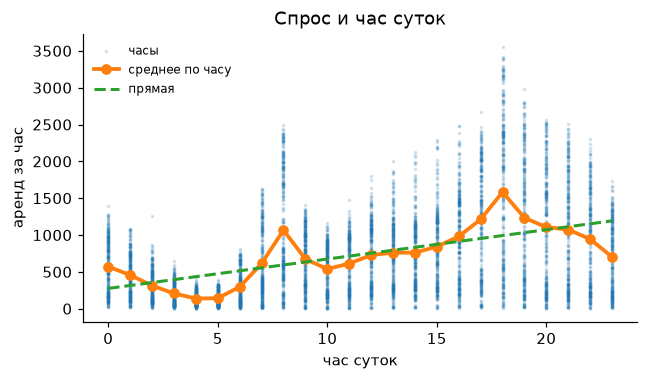

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
means = train.groupby("hour")["count"].mean()
ax.scatter(train["hour"], train["count"], s=2, alpha=.15, label="часы")
ax.plot(means.index, means.values, color="tab:orange", lw=2.5, marker="o", label="среднее по часу")
k, b = np.polyfit(train["hour"], train["count"], 1)
ax.plot([0, 23], [b, 23 * k + b], "--", color="tab:green", lw=2, label="прямая")
ax.set_xlabel("час суток")
ax.set_ylabel("аренд за час")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Спрос и час суток")
plt.show()

           uniform  quantile
4           0.5726    0.5848
8           0.6093    0.6071
12          0.6339    0.6379
20          0.6499    0.6510
24          0.6625    0.6590
без бинов   0.5391    0.5391


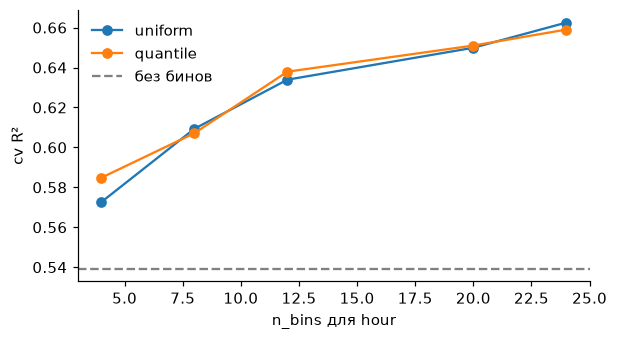

In [6]:
grid = [4, 8, 12, 20, 24]
res = {s: [cv_r2(make_pipeline(make_prep(n, s), LinearRegression())) for n in grid]
       for s in ["uniform", "quantile"]}
res = pd.DataFrame(res, index=grid).round(4)
res.loc["без бинов"] = round(cv_r2(make_pipeline(make_prep(), LinearRegression())), 4)
print(res)

fig, ax = plt.subplots(figsize=(6, 3.2))
for s in ["uniform", "quantile"]:
    ax.plot(grid, res.loc[grid, s], marker="o", label=s)
ax.axhline(res.loc["без бинов", "uniform"], ls="--", color="gray", label="без бинов")
ax.set_xlabel("n_bins для hour")
ax.set_ylabel("cv R²")
ax.legend(frameon=False)
plt.show()

Почему слишком много интервалов вредит, лучше видно на температуре. У неё больше 500 разных значений, и интервалов можно сделать сколько угодно.

In [7]:
tgrid = [4, 8, 20, 50, 100, 200, 400]
num_wo = [c for c in num_cols if c != "temp"]
def prep_temp(n):
    return make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), ["hour"] + num_wo),
        (KBinsDiscretizer(n_bins=n, encode="onehot", strategy="quantile"), ["temp"]),
        (OneHotEncoder(handle_unknown="ignore"), cat_cols))
small = train.sample(1000, random_state=0)  # на малой выборке эффект виден лучше
Xs, ys = small[["hour"] + num_cols + cat_cols], small["count"]
for n in tgrid:
    s = cross_val_score(make_pipeline(prep_temp(n), LinearRegression()), Xs, ys, cv=5, scoring="r2").mean()
    print(f"temp, n_bins={n:>3}: cv R² = {s:.4f}   (~{len(small) * 0.8 / n:.0f} объектов на интервал)")

temp, n_bins=  4: cv R² = 0.5064   (~200 объектов на интервал)
temp, n_bins=  8: cv R² = 0.5109   (~100 объектов на интервал)
temp, n_bins= 20: cv R² = 0.5255   (~40 объектов на интервал)
temp, n_bins= 50: cv R² = 0.5006   (~16 объектов на интервал)


temp, n_bins=100: cv R² = 0.4648   (~8 объектов на интервал)
temp, n_bins=200: cv R² = 0.3963   (~4 объектов на интервал)


temp, n_bins=400: cv R² = 0.2813   (~2 объектов на интервал)


**Вывод П3.**
- У спроса по часам два пика, утром и вечером, а прямая их не видит. С 24 интервалами часа, по одному на час, cv R² растёт с 0,539 до 0,663.
- `uniform` и `quantile` дают почти одно и то же, потому что все часы встречаются одинаково часто.
- Больше 24 интервалов для `hour` не сделать, у часа всего 24 значения. Поэтому качество растёт до конца сетки.
- На температуре видно, когда интервалов слишком много. При 20 интервалах в каждом около 40 объектов, и качество растёт. Дальше в интервал попадают единицы объектов, и его вес подстраивается под их шум. При 400 интервалах R² падает до 0,28. Это переобучение.
- В эксперимент `exp/bins` берём `hour_bins = 24`.

## П4. Регуляризация и подбор α

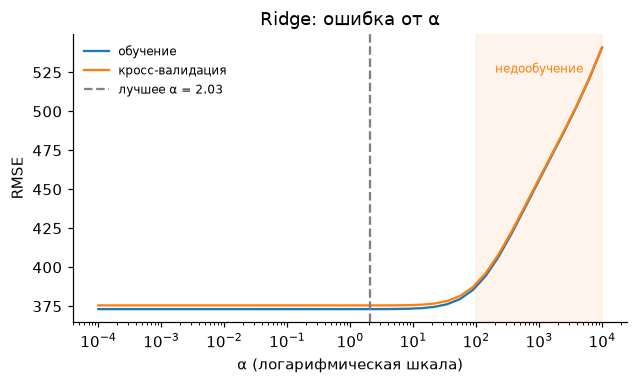

лучшее α: 2.031  cv RMSE: 376  train RMSE: 373
α=1e-4: train 373 cv 376 | α=1e4: train 541 cv 541


In [8]:
alphas = np.logspace(-4, 4, 40)
base_model = make_pipeline(make_prep(24), Ridge())
tr, cv = validation_curve(base_model, X_train, y_train, param_name="ridge__alpha",
                          param_range=alphas, cv=5, scoring="neg_root_mean_squared_error")
tr_rmse, cv_rmse = -tr.mean(axis=1), -cv.mean(axis=1)
best = alphas[np.argmin(cv_rmse)]

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.semilogx(alphas, tr_rmse, label="обучение")
ax.semilogx(alphas, cv_rmse, label="кросс-валидация")
ax.axvline(best, ls="--", color="gray", label=f"лучшее α = {best:.3g}")
ax.axvspan(1e2, 1e4, color="tab:orange", alpha=.08)
ax.text(2e2, cv_rmse.max() * 0.97, "недообучение", fontsize=8, color="tab:orange")
ax.set_xlabel("α (логарифмическая шкала)")
ax.set_ylabel("RMSE")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Ridge: ошибка от α")
plt.show()
print("лучшее α:", round(best, 3), " cv RMSE:", round(cv_rmse.min()), " train RMSE:", round(tr_rmse[np.argmin(cv_rmse)]))
print("α=1e-4: train", round(tr_rmse[0]), "cv", round(cv_rmse[0]), "| α=1e4: train", round(tr_rmse[-1]), "cv", round(cv_rmse[-1]))

In [9]:
def lasso_report(drop):
    m = make_pipeline(make_prep(24, drop=drop),
                      LassoCV(alphas=np.logspace(-2, 2, 30), cv=5, random_state=42, max_iter=50000))
    m.fit(X_train, y_train)
    names = [n.split("__")[1] for n in m[:-1].get_feature_names_out()]
    coef = pd.Series(m[-1].coef_, index=names)
    print(f"drop={drop}: alpha={m[-1].alpha_:.3f}, cv R²={cv_r2(m):.4f}, "
          f"обнулено {int((coef.abs() < 1e-6).sum())} из {len(coef)}:",
          list(coef[coef.abs() < 1e-6].index))
    return coef

coef_lasso = lasso_report(None)
coef_lasso_drop = lasso_report("first")

drop=None: alpha=0.067, cv R²=0.6625, обнулено 4 из 40: ['hour_0.0', 'season_Summer', 'holiday_No Holiday', 'weekend_yes']


drop=first: alpha=0.049, cv R²=0.6625, обнулено 1 из 37: ['hour_0.0']


**Вывод П4.**
- Переобучения при малых α на графике почти не видно. Ошибка на обучении 373, на кросс-валидации 376. На 6 348 объектах и 40 признаках модели не на чем переобучиться.
- Недообучение при α > 100 видно хорошо. Обе ошибки растут вместе, до 541 при α = 10⁴, потому что штраф прижимает все веса к нулю.
- Лучшее α ≈ 2,0 даёт cv RMSE 376, столько же, сколько без регуляризации.
- Lasso с α ≈ 0,067 обнулил 4 веса: `hour_0.0`, `season_Summer`, `holiday_No Holiday` и `weekend_yes`. Это по одному столбцу в каждой группе one-hot. Столбцы группы в сумме дают 1, поэтому один из них лишний.
- С `OneHotEncoder(drop="first")` первая категория уже удалена, и Lasso обнуляет только `hour_0.0`. Интервалы часа делает `KBinsDiscretizer`, на него `drop` не действует. Веса категорий теперь читаются относительно удалённой первой категории.

## П5. Интерпретация

In [10]:
best_model = make_pipeline(make_prep(24), LinearRegression()).fit(X_train, y_train)
names = [n.split("__")[1] for n in best_model[:-1].get_feature_names_out()]
weights = pd.Series(best_model[-1].coef_, index=names)

base = cv_r2(make_pipeline(make_prep(24), LinearRegression()))
drop = {}
for col in num_cols + cat_cols:
    nn = [c for c in num_cols if c != col]
    cc = [c for c in cat_cols if c != col]
    drop[col] = base - cv_r2(make_pipeline(make_prep(24, num=nn, cat=cc), LinearRegression()))
no_hour = make_column_transformer(  # все признаки, кроме hour
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    (OneHotEncoder(handle_unknown="ignore"), cat_cols))
drop["hour"] = base - cv_r2(make_pipeline(no_hour, LinearRegression()))
table = pd.DataFrame({"вес (на 1 ст. откл.)": weights.reindex(num_cols).round(0),
                      "падение R² без признака": pd.Series(drop).reindex(num_cols).round(4)})
print("базовый cv R²:", round(base, 4))
print(table)
print(pd.Series(drop).reindex(["hour"] + cat_cols).round(4))

базовый cv R²: 0.6625
            вес (на 1 ст. откл.)  падение R² без признака
temp                       118.0                   0.0000
humidity                  -222.0                   0.0053
wind                        -2.0                  -0.0001
visibility                  -3.0                  -0.0001
dew_point                  200.0                   0.0004
solar                       69.0                   0.0023
rainfall                   -67.0                   0.0094
snowfall                    11.0                   0.0002
hour       0.2013
season     0.0248
holiday    0.0017
weekend    0.0042
dtype: float64


In [11]:
print(X_train[num_cols].corr().round(2).loc[["temp", "dew_point", "humidity"], ["temp", "dew_point", "humidity"]])

           temp  dew_point  humidity
temp       1.00       0.91      0.16
dew_point  0.91       1.00      0.54
humidity   0.16       0.54      1.00


Цель скошена, асимметрия ≈ 1,15. Попробуем обучать модель на логарифме цели. Берём `log1p`, потому что бывают часы с 0 аренд.

In [12]:
log_model = make_pipeline(make_prep(24),
                          TransformedTargetRegressor(LinearRegression(), func=np.log1p, inverse_func=np.expm1))
print("cv R² с логарифмом цели:", round(cv_r2(log_model), 4), " без:", round(base, 4))
log_model.fit(X_train, y_train)
lw = pd.Series(log_model[-1].regressor_.coef_, index=names)
pct = ((np.exp(lw) - 1) * 100).round(1)
print(pct.reindex(num_cols + ["season_Summer", "season_Winter", "holiday_No Holiday", "weekend_yes"]).to_string())

cv R² с логарифмом цели: 0.6217  без: 0.6625
temp                  -31.6
humidity              -51.3
wind                   -4.1
visibility             -1.3
dew_point             167.5
solar                   8.0
rainfall              -23.2
snowfall               -0.9
season_Summer          10.2
season_Winter         -37.6
holiday_No Holiday     19.7
weekend_yes            -8.4


**Вывод П5.**
- Сильнее всего на спрос влияет час суток. Без него R² падает на 0,20. Дальше идут сезон (0,025), дождь и влажность.
- У `temp` большой вес, +118 аренд на одно стандартное отклонение. Но без `temp` R² не меняется, падение 0,0000. Дело в корреляции. У `temp` и `dew_point` она 0,91, ведь точку росы считают по температуре и влажности. Без `temp` ту же информацию дают `dew_point` и `humidity`.
- Большой вес не значит, что признак важен.
- С логарифмом цели качество хуже, cv R² 0,622 против 0,663, поэтому в модель его не берём. Зато веса можно читать в процентах по формуле (eʷ − 1) · 100 %. Зимой спрос на 37,6 % ниже. В обычный день, не праздник, на 19,7 % выше. В выходные на 8,4 % ниже.
- У `temp` (−31,6 %) и `dew_point` (+167,5 %) знаки разные. Это снова корреляция. Две почти одинаковые переменные делят вес между собой, и по отдельности их веса читать нельзя.